# Extending LangGraph to Multi-Agent

From a single ReAct agent to a supervisor routing across specialised researcher, writer, and critic roles.

| Primitive | What it is | Why it is here |
|-----------|------------|----------------|
| `MessagesState` | LangGraph's append-only message channel | The shared transcript every specialist reads and writes |
| `MultiAgentState` | Our TypedDict extension carrying per-role scratch slices | Each specialist owns its own slot — `researcher_notes`, `writer_draft`, `critique` |
| `Supervisor` | Pydantic schema with `Literal['researcher','writer','critic','done']` | Structured-output routing — the schema IS the control flow |
| `StateGraph` | LangGraph state-machine container | Holds the supervisor + 3 specialist nodes and the routing edges |

A single LangGraph agent is the wrong primitive the moment we want **specialised roles** — different system prompts, different tools, different scratch state. The supervisor pattern keeps the shared transcript in `MessagesState` while each specialist owns its own slice of `MultiAgentState`. 

## Setup

In [17]:
!pip install -q langchain langchain-openai langchain-google-genai langchain-anthropic langgraph pydantic python-dotenv

from langchain.chat_models import init_chat_model
from langchain.embeddings import init_embeddings
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from pydantic import BaseModel, Field
from typing import TypedDict, List, Optional, Literal, Annotated
from operator import add
import os, json
import warnings
warnings.filterwarnings("ignore")
from dotenv import load_dotenv
load_dotenv()


[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


True

In [18]:
llm   = init_chat_model('gpt-4o', model_provider='openai', temperature=0)
# llm   = init_chat_model('gemini-2.5-flash', model_provider='google_genai', temperature=0)

embed = init_embeddings('sentence-transformers/all-MiniLM-L6-v2', provider='huggingface')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## Why a single agent is not enough

Now let's name the failure mode we are extending past. A single ReAct agent shares ONE system prompt, ONE tool list, and ONE scratch.

Now, we will
- list the three frictions that show up the moment a single agent is asked to do two jobs,
- contrast a single-agent approach with a supervisor-of-specialists across role, tools, and state shape,
- print the contrast table so the WHO-vs-HOW framing is on screen before any code,
- set the bar for the supervisor pattern in the next section.

In [19]:
# Pattern: enumerate the frictions a single agent imposes when roles diverge.
single_agent_frictions = [
    ('system prompt', 'one prompt must cover research, drafting, and critique tones at once'),
    ('tool list',     'every tool is exposed to every step, so the agent can over-use or mis-route'),
    ('scratch state', 'one bag of variables, no per-role slot for notes vs draft vs critique'),
]

print('=== single-agent frictions ===')
for k, v in single_agent_frictions:
    print(f'  {k:<14} : {v}')

print('\n---- single agent vs supervisor-of-specialists ----')
rows = [
    ('role',          'one generalist',          'researcher / writer / critic'),
    ('system prompt', 'one shared prompt',       'one per specialist, pinned at construction'),
    ('tools',         'all tools, every step',   'whitelist per specialist'),
    ('state',         'one flat scratch',        'shared MessagesState + per-role slices'),
    ('routing',       'agent decides loop exit', 'supervisor routes via structured output'),
]
for k, single, multi in rows:
    print(f'  {k:<14} | single={single:<30} | multi={multi}')

=== single-agent frictions ===
  system prompt  : one prompt must cover research, drafting, and critique tones at once
  tool list      : every tool is exposed to every step, so the agent can over-use or mis-route
  scratch state  : one bag of variables, no per-role slot for notes vs draft vs critique

---- single agent vs supervisor-of-specialists ----
  role           | single=one generalist                 | multi=researcher / writer / critic
  system prompt  | single=one shared prompt              | multi=one per specialist, pinned at construction
  tools          | single=all tools, every step          | multi=whitelist per specialist
  state          | single=one flat scratch               | multi=shared MessagesState + per-role slices
  routing        | single=agent decides loop exit        | multi=supervisor routes via structured output


## The shared `MultiAgentState`

Now let's define the state that flows between supervisor and specialists. We extend `MessagesState`-style append semantics with one scratch slot per role.

Now, we will
- declare a `MultiAgentState` TypedDict with `messages` (annotated with `add` so it appends, like `MessagesState`),
- give each specialist its own scratch key — `researcher_notes`, `writer_draft`, `critique` — so roles do not clobber each other,
- carry an `iteration` counter and a `next_agent` slot for the supervisor's verdict,
- include a first-class `trace` so debugging reads the same audit log the runtime does.

In [20]:
class MultiAgentState(TypedDict):
    """Shared state for the supervisor + specialists graph. The `messages` channel
    behaves like LangGraph's MessagesState (annotated with `add`) so every specialist's
    output appends to the shared transcript. Each role owns its OWN scratch slot —
    no two specialists ever write to the same field."""
    messages:          Annotated[List, add]   # shared transcript, append-only like MessagesState
    researcher_notes:  str                    # researcher's scratch slot
    writer_draft:      str                    # writer's scratch slot
    critique:          str                    # critic's scratch slot
    iteration:         int                    # supervisor turn counter (cap enforced)
    next_agent:        str                    # supervisor's last routing verdict
    trace:             List[dict]             # first-class audit log of every hop

Per-role scratch is the structural move that makes specialists composable. The researcher writes to `researcher_notes`, the writer reads notes and writes `writer_draft`, the critic reads the draft and writes `critique`. Nothing is overwritten silently; the audit trail in `trace` records who ran when.

## The `Supervisor` schema

Now let's define the schema the supervisor's LLM call returns. The schema IS the control flow.

Now, we will
- declare a `Supervisor` Pydantic model with `next_agent: Literal['researcher','writer','critic','done']` and a short `reason`,
- bind a structured-output supervisor LLM via `with_structured_output(Supervisor)`,
- pin a `SUPERVISOR_PROMPT` upper-case constant that lays out who each specialist is and when to call `done`,
- print one example invocation so the routing shape is concrete before we wire the graph.

In [21]:
class Supervisor(BaseModel):
    """Structured routing verdict. Using `with_structured_output` makes the supervisor's
    decision MACHINE-READABLE so it feeds a conditional edge directly — no regex, no
    free-text heuristics, no second LLM call to parse the first one."""
    next_agent: Literal['researcher', 'writer', 'critic', 'done'] = Field(
        description="Which specialist runs next, or 'done' to finish.")
    reason: str = Field(description='One short sentence: why route there next.')

supervisor_llm = llm.with_structured_output(Supervisor)

In [22]:
SUPERVISOR_PROMPT = """You are the SUPERVISOR of a small writing team.

Specialists you can route to:
- researcher : gathers facts and writes them into `researcher_notes`. Run first when notes are empty.
- writer     : turns `researcher_notes` into a short draft in `writer_draft`. Run after notes exist.
- critic     : reviews `writer_draft` and writes a verdict into `critique`. Run after a draft exists.
- done       : the draft is acceptable and the critique is positive. End the run.

User task:
{task}

Current state snapshot:
- researcher_notes : {notes_status}
- writer_draft     : {draft_status}
- critique         : {critique_status}
- iteration        : {iteration}

Pick ONE next_agent and a one-sentence reason. Stop early with 'done' if the critique is positive.
"""

demo_verdict = supervisor_llm.invoke(SUPERVISOR_PROMPT.format(
    task='Write a one-paragraph explainer on agentic memory.',
    notes_status='empty', draft_status='empty', critique_status='empty', iteration=0,
))
print('=== example supervisor verdict ===')
print(json.dumps(demo_verdict.model_dump(), indent=2))

=== example supervisor verdict ===
{
  "next_agent": "researcher",
  "reason": "Researcher needs to gather initial facts on agentic memory as the notes are currently empty."
}


## The three specialist nodes

Now let's give each role its own LLM call, its own system prompt, and its own scratch slot. This is where role conditioning becomes a first-class primitive.

Now, we will
- define three upper-case prompt constants — `RESEARCHER_PROMPT`, `WRITER_PROMPT`, `CRITIC_PROMPT` — so each role's voice is pinned,
- write `researcher_node`, `writer_node`, and `critic_node`, each calling `llm.invoke` with its OWN system prompt,
- have each node return ONLY the slice of state it owns (`researcher_notes`, `writer_draft`, `critique`) plus an `AIMessage` for the shared transcript,
- append a `trace` row from each node so we can audit who ran when.

In [23]:
RESEARCHER_PROMPT = """You are the RESEARCHER on a writing team.

Your one job: produce a tight, factual notes block on the user's task.
Constraints:
- 4 to 6 short bullet points, each one fact.
- No prose, no opinions, no draft sentences. Notes only.
- Stay in role. Do NOT write the final paragraph.

Task: {task}
"""

def researcher_node(state: MultiAgentState) -> dict:
    """Run the researcher specialist. Writes into `researcher_notes` and appends one
    AIMessage to the shared transcript so downstream specialists can see the handoff."""
    task = state['messages'][0].content
    out = llm.invoke([
        SystemMessage(content=RESEARCHER_PROMPT.format(task=task)),
        HumanMessage(content='Produce the notes now.'),
    ])
    notes = out.content
    trace = state['trace'] + [{
        'iter': state['iteration'], 'event': 'researcher',
        'preview': notes[:120] + '...' if len(notes) > 120 else notes,
    }]
    return {
        'researcher_notes': notes,
        'messages': [AIMessage(content=f'[researcher] {notes[:120]}...', name='researcher')],
        'trace': trace,
    }

Notice the writer reads `researcher_notes` directly out of state — that is the per-role state slice paying off. We never have to pass notes through the shared transcript by hand.

In [24]:
WRITER_PROMPT = """You are the WRITER on a writing team.

Your one job: turn the researcher's notes into ONE short paragraph (3 to 5 sentences).
Constraints:
- Write prose, not bullets.
- Stay grounded in the notes. Do NOT introduce facts that are not in the notes.
- Stay in role. Do NOT critique your own draft.

Task: {task}

Researcher notes:
{notes}
"""

def writer_node(state: MultiAgentState) -> dict:
    """Run the writer specialist. Reads `researcher_notes`, writes `writer_draft`."""
    task  = state['messages'][0].content
    notes = state['researcher_notes'] or '(no notes yet)'
    out = llm.invoke([
        SystemMessage(content=WRITER_PROMPT.format(task=task, notes=notes)),
        HumanMessage(content='Write the paragraph now.'),
    ])
    draft = out.content
    trace = state['trace'] + [{
        'iter': state['iteration'], 'event': 'writer',
        'preview': draft[:120] + '...' if len(draft) > 120 else draft,
    }]
    return {
        'writer_draft': draft,
        'messages': [AIMessage(content=f'[writer] {draft[:120]}...', name='writer')],
        'trace': trace,
    }

The critic gets a structured verdict so the supervisor in the next iteration can trivially read `critique` and decide whether to stop. A free-text critique would force the supervisor to re-parse natural language.

In [25]:
CRITIC_PROMPT = """You are the CRITIC on a writing team.

Your one job: judge the writer's draft against the researcher's notes.
Constraints:
- Reply in two short lines: VERDICT: <accept|revise> and REASON: <one sentence>.
- Accept if the draft is grounded, clear, and on-task.
- Stay in role. Do NOT rewrite the draft yourself.

Task: {task}

Researcher notes:
{notes}

Writer draft:
{draft}
"""

def critic_node(state: MultiAgentState) -> dict:
    """Run the critic specialist. Reads draft + notes, writes `critique`."""
    task  = state['messages'][0].content
    notes = state['researcher_notes'] or '(no notes yet)'
    draft = state['writer_draft']     or '(no draft yet)'
    out = llm.invoke([
        SystemMessage(content=CRITIC_PROMPT.format(task=task, notes=notes, draft=draft)),
        HumanMessage(content='Judge the draft now.'),
    ])
    critique = out.content
    trace = state['trace'] + [{
        'iter': state['iteration'], 'event': 'critic',
        'preview': critique[:120] + '...' if len(critique) > 120 else critique,
    }]
    return {
        'critique': critique,
        'messages': [AIMessage(content=f'[critic] {critique[:120]}...', name='critic')],
        'trace': trace,
    }

## The supervisor node and conditional edge

Now let's wire the supervisor itself. It calls the structured LLM, writes `next_agent` into state, and a tiny pure router maps that string to the next node.

Now, we will
- define `MAX_TURNS = 6` as a hard cap so the loop cannot recurse unboundedly,
- write `supervisor_node` that bumps `iteration`, calls `supervisor_llm`, and force-routes to `done` past the cap,
- write `route_supervisor` — a one-line pure function that reads `next_agent` and returns the node name (or `END`),
- record every routing verdict in `trace` so we can audit which specialist the supervisor picked at each turn.

In [26]:
MAX_TURNS = 6

def _status(s: str) -> str:
    """Compact status string for the supervisor prompt: 'empty' or a 60-char preview."""
    if not s:
        return 'empty'
    return (s[:60] + '...') if len(s) > 60 else s

def supervisor_node(state: MultiAgentState) -> dict:
    """Run the supervisor: pick the next specialist (or done). Force-terminates at MAX_TURNS"""
    iteration = state['iteration'] + 1
    task = state['messages'][0].content
    verdict: Supervisor = supervisor_llm.invoke(SUPERVISOR_PROMPT.format(
        task=task,
        notes_status=_status(state['researcher_notes']),
        draft_status=_status(state['writer_draft']),
        critique_status=_status(state['critique']),
        iteration=iteration,
    ))

    # Force termination at the cap — the supervisor MUST commit to done.
    if iteration >= MAX_TURNS and verdict.next_agent != 'done':
        verdict = Supervisor(next_agent='done',
                             reason=f'force-stop at MAX_TURNS={MAX_TURNS}')

    trace = state['trace'] + [{
        'iter': iteration, 'event': 'supervisor',
        'next_agent': verdict.next_agent, 'reason': verdict.reason[:90],
    }]
    return {
        'iteration': iteration,
        'next_agent': verdict.next_agent,
        'trace': trace,
    }

The router below is intentionally a 3-line pure function. Keeping routing logic separate from the supervisor node body is the LangGraph convention — the node *decides*, the router *maps*.

In [27]:
def route_supervisor(state: MultiAgentState) -> str:
    """Map the supervisor's `next_agent` string to a graph node name (or END)."""
    nxt = state['next_agent']
    return END if nxt == 'done' else nxt

## Compiling the multi-agent graph

Now let's assemble supervisor + 3 specialists into one `StateGraph`. After each specialist runs, control returns to the supervisor — that loop is the supervisor pattern.

Now, we will
- create a `StateGraph(MultiAgentState)` builder and add four nodes: `supervisor`, `researcher`, `writer`, `critic`,
- set the entry edge `START -> supervisor`, then add a conditional edge from `supervisor` mapping each specialist name to its node and `'done'` to `END`,
- add plain edges from every specialist back to `supervisor` so the loop closes,
- compile to `app` and print the node names so the wiring is visible before the mermaid render.

In [28]:
builder = StateGraph(MultiAgentState)
builder.add_node('supervisor', supervisor_node)
builder.add_node('researcher', researcher_node)
builder.add_node('writer',     writer_node)
builder.add_node('critic',     critic_node)

builder.add_edge(START, 'supervisor')
builder.add_conditional_edges(
    'supervisor',
    route_supervisor,
    {'researcher': 'researcher', 'writer': 'writer', 'critic': 'critic', END: END},
)
builder.add_edge('researcher', 'supervisor')
builder.add_edge('writer',     'supervisor')
builder.add_edge('critic',     'supervisor')

app = builder.compile()
print('Graph compiled with nodes:', list(builder.nodes.keys()))

Graph compiled with nodes: ['supervisor', 'researcher', 'writer', 'critic']


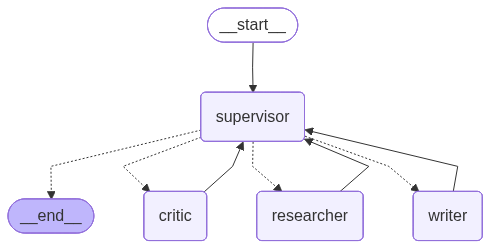

In [29]:
app

## Running the team on a writing task

Finally, let's invoke the compiled graph on a real writing task and watch the handoffs in the trace.

Now, we will
- prime the initial `MultiAgentState` with one `HumanMessage` carrying the task and empty scratch slots,
- invoke `app` and capture the final state,
- print the supervisor-and-specialist `trace` so the routing decisions are auditable,
- print the final `writer_draft`, `critique`, and the message thread under banner separators.

*Tip: prime `iteration=0` and let `supervisor_node` bump it. That keeps the cap logic in ONE place.*

In [30]:
TASK = 'Write a one-paragraph explainer for engineers on what agentic memory is and why it matters.'

initial: MultiAgentState = {
    'messages':         [HumanMessage(content=TASK)],
    'researcher_notes': '',
    'writer_draft':     '',
    'critique':         '',
    'iteration':        0,
    'next_agent':       '',
    'trace':            [],
}

result = app.invoke(initial, config={'recursion_limit': 25})

print('=== TRACE ===')
for step in result['trace']:
    print(json.dumps(step, indent=2))

=== TRACE ===
{
  "iter": 1,
  "event": "supervisor",
  "next_agent": "researcher",
  "reason": "The researcher should gather facts about agentic memory since the notes are currently empt"
}
{
  "iter": 1,
  "event": "researcher",
  "preview": "- Agentic memory refers to the ability to recall past actions and decisions as being self-initiated and goal-directed.\n-..."
}
{
  "iter": 2,
  "event": "supervisor",
  "next_agent": "writer",
  "reason": "Researcher notes are available, so the writer can now create a draft."
}
{
  "iter": 2,
  "event": "writer",
  "preview": "Agentic memory is the capacity to remember past actions and decisions as self-initiated and goal-directed, forming a key..."
}
{
  "iter": 3,
  "event": "supervisor",
  "next_agent": "critic",
  "reason": "The writer has completed a draft, so it's time for the critic to review it and provide fee"
}
{
  "iter": 3,
  "event": "critic",
  "preview": "VERDICT: accept\nREASON: The draft is grounded, clear, and aligns well with

Now the artefacts each specialist produced. Per-role scratch means we can read each slice directly out of the final state — no string parsing, no re-running the LLM to extract anything.

In [31]:
print('=== RESEARCHER NOTES ===')
print(result['researcher_notes'])

print('\n=== WRITER DRAFT ===')
print(result['writer_draft'])

print('\n=== CRITIQUE ===')
print(result['critique'])

print(f'\n---- iterations: {result["iteration"]}  final next_agent: {result["next_agent"]} ----')

=== RESEARCHER NOTES ===
- Agentic memory refers to the ability to recall past actions and decisions as being self-initiated and goal-directed.
- It is a component of autobiographical memory, which involves personal experiences and events.
- Plays a crucial role in self-identity and understanding one's own agency in past events.
- Important for decision-making processes, as it helps individuals learn from past actions.
- In engineering, understanding agentic memory can aid in designing systems that support user autonomy and personalized experiences.

=== WRITER DRAFT ===
Agentic memory is the capacity to remember past actions and decisions as self-initiated and goal-directed, forming a key part of autobiographical memory, which encompasses personal experiences and events. This type of memory is crucial for shaping self-identity and understanding one's own role in past events, thereby influencing decision-making processes by allowing individuals to learn from their previous actions. For

Finally the shared transcript. Each specialist appended one short marker `AIMessage` so we can confirm the handoff order from the supervisor's point of view, separately from the audit `trace`.

In [32]:
print('---- shared message thread ----')
for m in result['messages']:
    name = getattr(m, 'name', None) or m.__class__.__name__
    body = m.content[:120] + '...' if len(m.content) > 120 else m.content
    print(f'  [{name}] {body}')

---- shared message thread ----
  [HumanMessage] Write a one-paragraph explainer for engineers on what agentic memory is and why it matters.
  [researcher] [researcher] - Agentic memory refers to the ability to recall past actions and decisions as being self-initiated and goa...
  [writer] [writer] Agentic memory is the capacity to remember past actions and decisions as self-initiated and goal-directed, form...
  [critic] [critic] VERDICT: accept
REASON: The draft is grounded, clear, and aligns well with the researcher's notes....


### Designing supervisor-of-specialists graphs in production
- Always cap supervisor turns, never trust the LLM to self-stop.
- Pin role conditioning at construction time. Each specialist's system prompt is an upper-case constant baked into its `_node` function, not rebuilt per call. A specialist that builds its prompt fresh each step will drift its tone within one run.


### Common pitfalls in multi-agent LangGraph
- Two specialists writing to the SAME state key will silently overwrite each other. <br>Mitigation: per-role scratch slots (`researcher_notes`, `writer_draft`, `critique`) are non-overlapping by design.
- The shared `messages` channel must be `Annotated[List, add]` (or use `MessagesState`) — without the reducer, every specialist's return value REPLACES the transcript instead of appending to it.
- Supervisor loops can flap (researcher -> writer -> researcher -> writer ...) when the supervisor prompt is fuzzy about end conditions. <br>Mitigation: make the `done` criterion explicit in `SUPERVISOR_PROMPT` and pair it with the `MAX_TURNS` hard cap.
- Off-policy handoffs — a specialist returning more than its own slice — break composability. Each `_node` should return ONLY the keys it owns plus its one `AIMessage` for the transcript.